# House Price Prediction — Regression with 3 Models

**Pipeline:** load `data.csv` → preprocess → 70/30 train/test split → train **Linear Regression (Ridge)**, **Neural Network (MLP)**, **Gradient Boosting** → combine them in a **Stacking Ensemble** → evaluate → plot (including loss vs. epoch curves).

**Note on metrics:** accuracy, precision, recall and F1 are *classification* metrics, and price is a continuous target. To report them, the true and predicted prices are both grouped into 3 price bands (**Low / Medium / High**) using the 33rd and 66th percentiles of the training prices. The classification metrics are computed on those bands. Standard regression metrics (R², MAE, RMSE) are also reported.

In [1]:
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.compose import ColumnTransformer
from copy import deepcopy
from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.pipeline import Pipeline
from sklearn.compose import TransformedTargetRegressor
from sklearn.linear_model import Ridge
from sklearn.neural_network import MLPRegressor
from sklearn.ensemble import GradientBoostingRegressor, StackingRegressor
from sklearn.metrics import (r2_score, mean_absolute_error, mean_squared_error,
                             accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix)

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
plt.rcParams["figure.dpi"] = 110
COLORS = ["#4C72B0", "#55A868", "#C44E52", "#8172B3"]

## 1. Load the dataset

In [2]:
df = pd.read_csv("data.csv")
print("Shape:", df.shape)
df.head()

Shape: (4600, 18)


,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated,street,city,statezip,country
0,2014-05-02 00:00:00,313000.0,3.0,1.50,1340,7912,1.5,0,0,3,1340,0,1955,2005,18810 Densmore Ave N,Shoreline,WA 98133,USA
1,2014-05-02 00:00:00,2384000.0,5.0,2.50,3650,9050,2.0,0,4,5,3370,280,1921,0,709 W Blaine St,Seattle,WA 98119,USA
2,2014-05-02 00:00:00,342000.0,3.0,2.00,1930,11947,1.0,0,0,4,1930,0,1966,0,26206-26214 143rd Ave SE,Kent,WA 98042,USA
3,2014-05-02 00:00:00,420000.0,3.0,2.25,2000,8030,1.0,0,0,4,1000,1000,1963,0,857 170th Pl NE,Bellevue,WA 98008,USA
4,2014-05-02 00:00:00,550000.0,4.0,2.50,1940,10500,1.0,0,0,4,1140,800,1976,1992,9105 170th Ave NE,Redmond,WA 98052,USA


In [3]:
df.info()
print("\nMissing values per column:\n", df.isna().sum())

<class 'pandas.DataFrame'>
RangeIndex: 4600 entries, 0 to 4599
Data columns (total 18 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   date           4600 non-null   str    
 1   price          4600 non-null   float64
 2   bedrooms       4600 non-null   float64
 3   bathrooms      4600 non-null   float64
 4   sqft_living    4600 non-null   int64  
 5   sqft_lot       4600 non-null   int64  
 6   floors         4600 non-null   float64
 7   waterfront     4600 non-null   int64  
 8   view           4600 non-null   int64  
 9   condition      4600 non-null   int64  
 10  sqft_above     4600 non-null   int64  
 11  sqft_basement  4600 non-null   int64  
 12  yr_built       4600 non-null   int64  
 13  yr_renovated   4600 non-null   int64  
 14  street         4600 non-null   str    
 15  city           4600 non-null   str    
 16  statezip       4600 non-null   str    
 17  country        4600 non-null   str    
dtypes: float64(4), int6

In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
price,4600.0,551962.988473,563834.702547,0.0,322875.00,460943.461539,654962.50,26590000.0
bedrooms,4600.0,3.400870,0.908848,0.0,3.00,3.000000,4.00,9.0
bathrooms,4600.0,2.160815,0.783781,0.0,1.75,2.250000,2.50,8.0
sqft_living,4600.0,2139.346957,963.206916,370.0,1460.00,1980.000000,2620.00,13540.0
sqft_lot,4600.0,14852.516087,35884.436145,638.0,5000.75,7683.000000,11001.25,1074218.0
floors,4600.0,1.512065,0.538288,1.0,1.00,1.500000,2.00,3.5
waterfront,4600.0,0.007174,0.084404,0.0,0.00,0.000000,0.00,1.0
view,4600.0,0.240652,0.778405,0.0,0.00,0.000000,0.00,4.0
condition,4600.0,3.451739,0.677230,1.0,3.00,3.000000,4.00,5.0
sqft_above,4600.0,1827.265435,862.168977,370.0,1190.00,1590.000000,2300.00,9410.0


## 2. Preprocessing
- Drop rows with `price == 0` (invalid) and extreme outliers (top 1% of price)
- Feature engineering: house age, renovated flag, years since renovation, sale month, zipcode, basement flag, log of the square-footage columns
- Drop columns that are useless or constant: `street` (almost unique), `country` (single value), `date`, `statezip`
- Log-transform the target to reduce skew (predictions are converted back to dollars)

In [5]:
data = df.copy()
print("Rows with price == 0:", (data["price"] == 0).sum())
data = data[data["price"] > 0]
data = data[data["price"] < data["price"].quantile(0.99)]
data = data.drop_duplicates()

data["date"] = pd.to_datetime(data["date"])
data["sale_year"] = data["date"].dt.year
data["sale_month"] = data["date"].dt.month
data["house_age"] = data["sale_year"] - data["yr_built"]
data["is_renovated"] = (data["yr_renovated"] > 0).astype(int)
data["yrs_since_renov"] = np.where(data["yr_renovated"] > 0,
                                   data["sale_year"] - data["yr_renovated"],
                                   data["house_age"])
data["zipcode"] = data["statezip"].str.extract(r"(\d+)")[0]
data["has_basement"] = (data["sqft_basement"] > 0).astype(int)
for col in ["sqft_living", "sqft_lot", "sqft_above"]:
    data[f"log_{col}"] = np.log1p(data[col])   # sizes are skewed; log makes them closer to linear in log-price

data = data.drop(columns=["date", "street", "country", "statezip", "yr_renovated", "sale_year"])
print("Shape after cleaning:", data.shape)
data.head()

Rows with price == 0: 49
Shape after cleaning: (4505, 22)


,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,...,city,sale_month,house_age,is_renovated,yrs_since_renov,zipcode,has_basement,log_sqft_living,log_sqft_lot,log_sqft_above
0,313000.0,3.0,1.50,1340,7912,1.5,0,0,3,1340,...,Shoreline,5,59,1,9,98133,0,7.201171,8.976262,7.201171
2,342000.0,3.0,2.00,1930,11947,1.0,0,0,4,1930,...,Kent,5,48,0,48,98042,0,7.565793,9.388319,7.565793
3,420000.0,3.0,2.25,2000,8030,1.0,0,0,4,1000,...,Bellevue,5,51,0,51,98008,1,7.601402,8.991064,6.908755
4,550000.0,4.0,2.50,1940,10500,1.0,0,0,4,1140,...,Redmond,5,38,1,22,98052,1,7.570959,9.259226,7.039660
5,490000.0,2.0,1.00,880,6380,1.0,0,0,3,880,...,Seattle,5,76,1,20,98115,0,6.781058,8.761080,6.781058


### Correlation heatmap (numeric features)

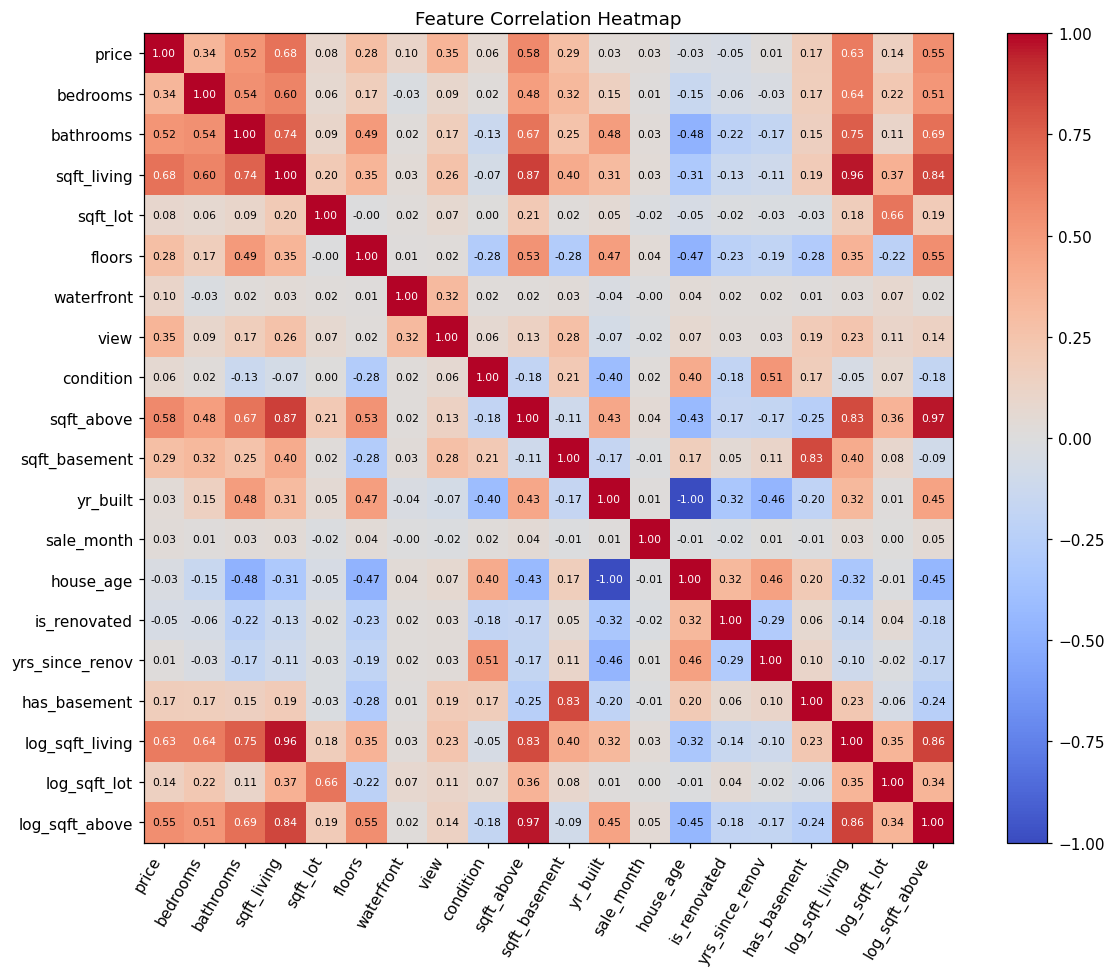

In [6]:
num_df = data.select_dtypes(include=np.number)
corr = num_df.corr()

fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=60, ha="right")
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7,
                color="white" if abs(corr.iloc[i, j]) > 0.6 else "black")
fig.colorbar(im, ax=ax, fraction=0.046)
ax.set_title("Feature Correlation Heatmap")
plt.tight_layout(); plt.show()

### Price distribution

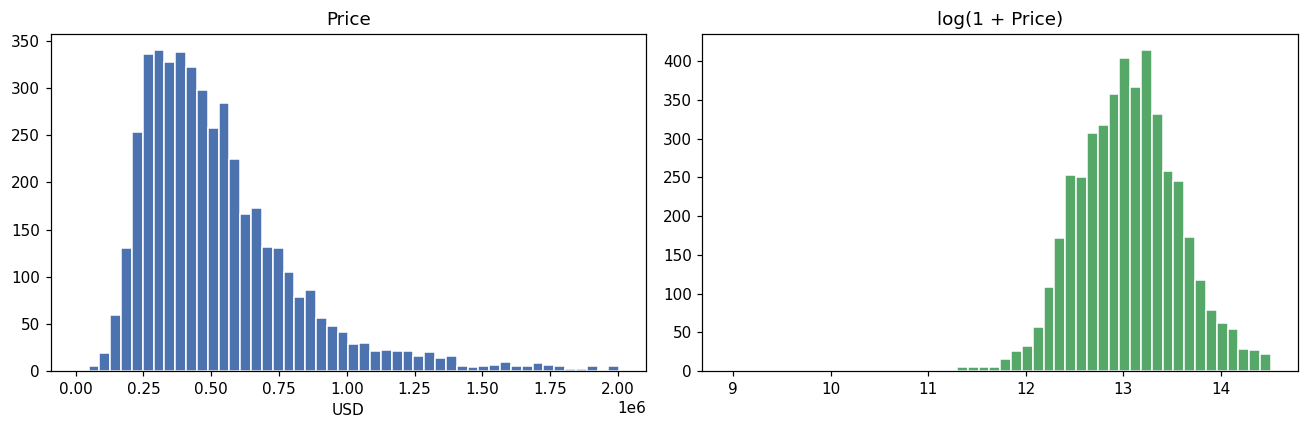

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(data["price"], bins=50, color="#4C72B0", edgecolor="white")
axes[0].set_title("Price"); axes[0].set_xlabel("USD")
axes[1].hist(np.log1p(data["price"]), bins=50, color="#55A868", edgecolor="white")
axes[1].set_title("log(1 + Price)")
plt.tight_layout(); plt.show()

## 3. Train / test split (70 / 30)

In [8]:
X = data.drop(columns=["price"])
y = data["price"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=RANDOM_STATE)
print("Train:", X_train.shape, " Test:", X_test.shape)

cat_cols = ["city", "zipcode"]
num_cols = [c for c in X.columns if c not in cat_cols]

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
])

# Price bands for the classification metrics, using training-set percentiles only
bins = [-np.inf, *y_train.quantile([0.33, 0.66]).values, np.inf]
labels = ["Low", "Medium", "High"]
to_band = lambda p: pd.cut(p, bins=bins, labels=labels)
print("Band edges (USD):", [round(b) for b in bins[1:-1]])

Train: (3153, 21)  Test: (1352, 21)
Band edges (USD): [365080, 565000]


## 4. Define the models
- **Linear Regression (Ridge)**: linear model with L2 regularisation.
- **Neural Network (MLP)**: trained one epoch at a time so train/validation loss can be recorded per epoch. 15% of the *training* set is held out for validation; the weights from the epoch with the lowest validation loss are kept (early stopping). The test set is never used for training or model selection.
- **Gradient Boosting**: 600 shallow trees; each tree added counts as one training iteration.
- **Stacking Ensemble**: combines the three models above. A Ridge meta-model learns how to weight their predictions using 5-fold out-of-fold predictions on the training set.

All models are trained on the standardised log-price and their predictions are converted back to dollars.

In [9]:
class EpochMLP(BaseEstimator, RegressorMixin):
    """MLPRegressor trained epoch by epoch, recording train/validation loss, with early stopping."""

    def __init__(self, hidden_layer_sizes=(64, 32), alpha=1.0, learning_rate_init=1e-3,
                 max_epochs=300, patience=30, val_size=0.15, random_state=RANDOM_STATE):
        self.hidden_layer_sizes = hidden_layer_sizes
        self.alpha = alpha
        self.learning_rate_init = learning_rate_init
        self.max_epochs = max_epochs
        self.patience = patience
        self.val_size = val_size
        self.random_state = random_state

    def fit(self, X, y):
        X_tr, X_val, y_tr, y_val = train_test_split(
            X, y, test_size=self.val_size, random_state=self.random_state)
        net = MLPRegressor(hidden_layer_sizes=self.hidden_layer_sizes, alpha=self.alpha,
                           learning_rate_init=self.learning_rate_init, random_state=self.random_state)
        self.train_loss_, self.val_loss_ = [], []
        best, wait = np.inf, 0
        for epoch in range(1, self.max_epochs + 1):
            net.partial_fit(X_tr, y_tr)
            self.train_loss_.append(mean_squared_error(y_tr, net.predict(X_tr)))
            self.val_loss_.append(mean_squared_error(y_val, net.predict(X_val)))
            if self.val_loss_[-1] < best - 1e-6:
                best, wait = self.val_loss_[-1], 0
                self.net_, self.best_epoch_ = deepcopy(net), epoch
            else:
                wait += 1
                if wait >= self.patience:
                    break
        return self

    def predict(self, X):
        return self.net_.predict(X)


# log(price) followed by standardisation; the inverse maps predictions back to dollars
target_transform = Pipeline([
    ("log", FunctionTransformer(np.log1p, inverse_func=np.expm1, check_inverse=False)),
    ("scale", StandardScaler()),
])

def make_model(reg):
    pipe = Pipeline([("prep", preprocessor), ("reg", reg)])
    return TransformedTargetRegressor(regressor=pipe, transformer=target_transform)

base_models = {
    "Linear Regression (Ridge)": make_model(Ridge(alpha=1.0)),
    "Neural Network (MLP)": make_model(EpochMLP(hidden_layer_sizes=(64, 32), alpha=1.0)),
    "Gradient Boosting": make_model(GradientBoostingRegressor(
        n_estimators=600, learning_rate=0.03, max_depth=4, subsample=0.8,
        random_state=RANDOM_STATE)),
}

stacking = StackingRegressor(
    estimators=[("ridge", base_models["Linear Regression (Ridge)"]),
                ("mlp", base_models["Neural Network (MLP)"]),
                ("gb", base_models["Gradient Boosting"])],
    final_estimator=Ridge(alpha=1.0), cv=5, n_jobs=-1)

models = {**base_models, "Stacking Ensemble": stacking}

## 5. Train and evaluate

In [10]:
results, predictions = [], {}

for name, model in models.items():
    start = time.perf_counter()
    model.fit(X_train, y_train)
    train_time = time.perf_counter() - start

    y_pred = model.predict(X_test)
    predictions[name] = y_pred

    y_true_band, y_pred_band = to_band(y_test), to_band(y_pred)
    results.append({
        "Model": name,
        "R2": r2_score(y_test, y_pred),
        "MAE": mean_absolute_error(y_test, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
        "Accuracy": accuracy_score(y_true_band, y_pred_band),
        "Precision": precision_score(y_true_band, y_pred_band, average="weighted"),
        "Recall": recall_score(y_true_band, y_pred_band, average="weighted"),
        "F1": f1_score(y_true_band, y_pred_band, average="weighted"),
        "Train Time (s)": train_time,
    })
    print(f"{name:<28} trained in {train_time:.2f}s")

results_df = pd.DataFrame(results).set_index("Model")
results_df.style.format({
    "R2": "{:.4f}", "MAE": "${:,.0f}", "RMSE": "${:,.0f}", "Accuracy": "{:.4f}",
    "Precision": "{:.4f}", "Recall": "{:.4f}", "F1": "{:.4f}", "Train Time (s)": "{:.3f}"
}).highlight_max(subset=["R2", "Accuracy", "Precision", "Recall", "F1"], color="#c6efce")

Linear Regression (Ridge)    trained in 0.13s


Neural Network (MLP)         trained in 5.01s


Gradient Boosting            trained in 17.69s


Stacking Ensemble            trained in 47.92s


,R2,MAE,RMSE,Accuracy,Precision,Recall,F1,Train Time (s)
Model,,,,,,,,
Linear Regression (Ridge),0.8013,"$79,150","$127,004",0.8143,0.8156,0.8143,0.8149,0.127
Neural Network (MLP),0.7753,"$81,576","$135,049",0.8121,0.8137,0.8121,0.8127,5.011
Gradient Boosting,0.7598,"$86,789","$139,624",0.8047,0.8104,0.8047,0.8066,17.691
Stacking Ensemble,0.8040,"$77,855","$126,148",0.8166,0.8202,0.8166,0.8175,47.921


## 6. Loss vs. epoch
Both curves use MSE on the standardised log-price.
- **Neural Network:** one epoch = one pass over the training data. The validation curve uses the 15% of the training set held out for validation. The dashed line marks the epoch whose weights were kept.
- **Gradient Boosting:** one iteration = one tree added. The test curve is shown for illustration only; it was not used to choose the number of trees.

Ridge regression is solved in closed form (in one step, with no iterative training), so it has no loss curve.

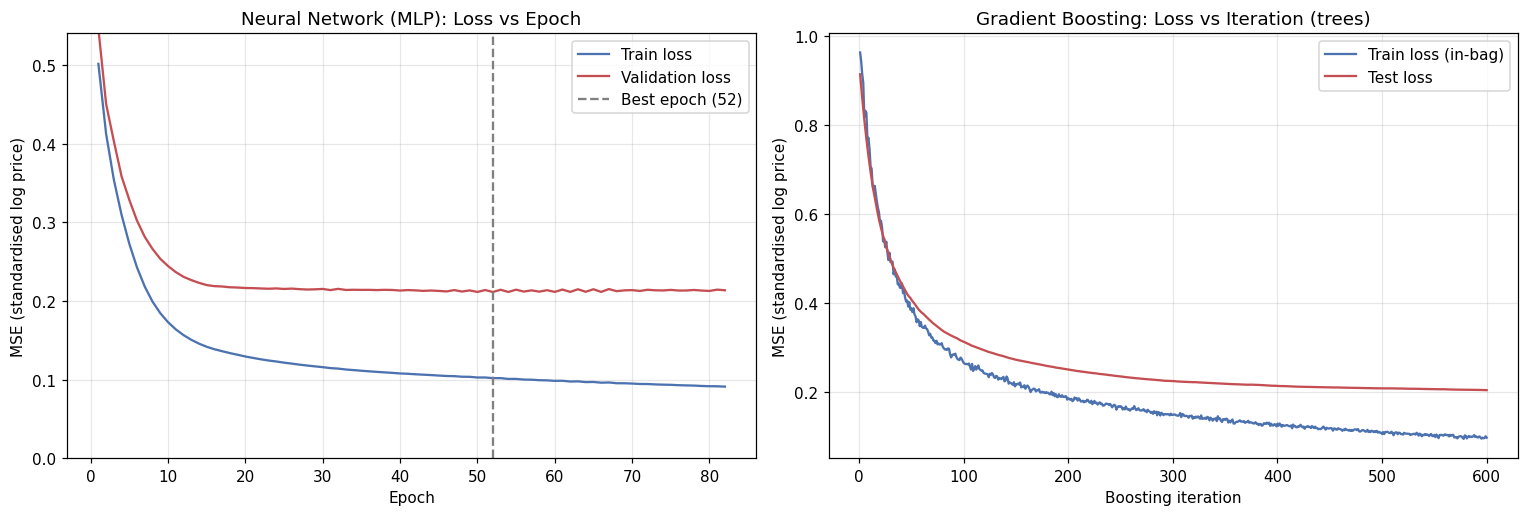

In [11]:
mlp = models["Neural Network (MLP)"].regressor_.named_steps["reg"]

gb_tt = models["Gradient Boosting"]
gb_pipe = gb_tt.regressor_
gb = gb_pipe.named_steps["reg"]
X_test_prep = gb_pipe.named_steps["prep"].transform(X_test)
y_test_t = gb_tt.transformer_.transform(y_test.to_frame().values).ravel()
gb_test_loss = [mean_squared_error(y_test_t, p) for p in gb.staged_predict(X_test_prep)]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
ep = range(1, len(mlp.train_loss_) + 1)
axes[0].plot(ep, mlp.train_loss_, label="Train loss", color="#4C72B0")
axes[0].plot(ep, mlp.val_loss_, label="Validation loss", color="#C44E52")
axes[0].axvline(mlp.best_epoch_, ls="--", color="gray", label=f"Best epoch ({mlp.best_epoch_})")
axes[0].set_title("Neural Network (MLP): Loss vs Epoch")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("MSE (standardised log price)")
axes[0].set_ylim(0, max(mlp.val_loss_[1:]) * 1.2)

it = range(1, gb.n_estimators_ + 1)
axes[1].plot(it, gb.train_score_, label="Train loss (in-bag)", color="#4C72B0")
axes[1].plot(it, gb_test_loss, label="Test loss", color="#C44E52")
axes[1].set_title("Gradient Boosting: Loss vs Iteration (trees)")
axes[1].set_xlabel("Boosting iteration"); axes[1].set_ylabel("MSE (standardised log price)")

for ax in axes:
    ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 7. Visualisations
### 7.1 Metric heatmap (models × metrics)

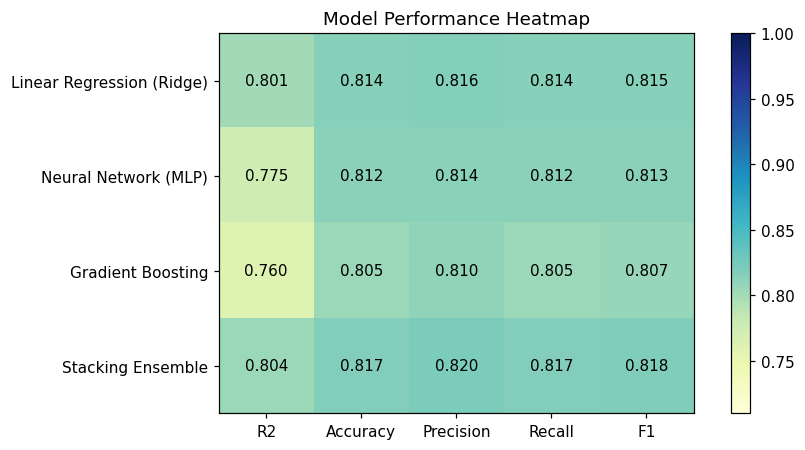

In [12]:
score_cols = ["R2", "Accuracy", "Precision", "Recall", "F1"]
m = results_df[score_cols]

fig, ax = plt.subplots(figsize=(8, 4.2))
im = ax.imshow(m.values, cmap="YlGnBu", vmin=m.values.min() - 0.05, vmax=1)
ax.set_xticks(range(len(score_cols))); ax.set_xticklabels(score_cols)
ax.set_yticks(range(len(m))); ax.set_yticklabels(m.index)
for i in range(m.shape[0]):
    for j in range(m.shape[1]):
        ax.text(j, i, f"{m.values[i, j]:.3f}", ha="center", va="center")
fig.colorbar(im, ax=ax)
ax.set_title("Model Performance Heatmap")
plt.tight_layout(); plt.show()

### 7.2 Confusion matrix heatmaps (price bands)

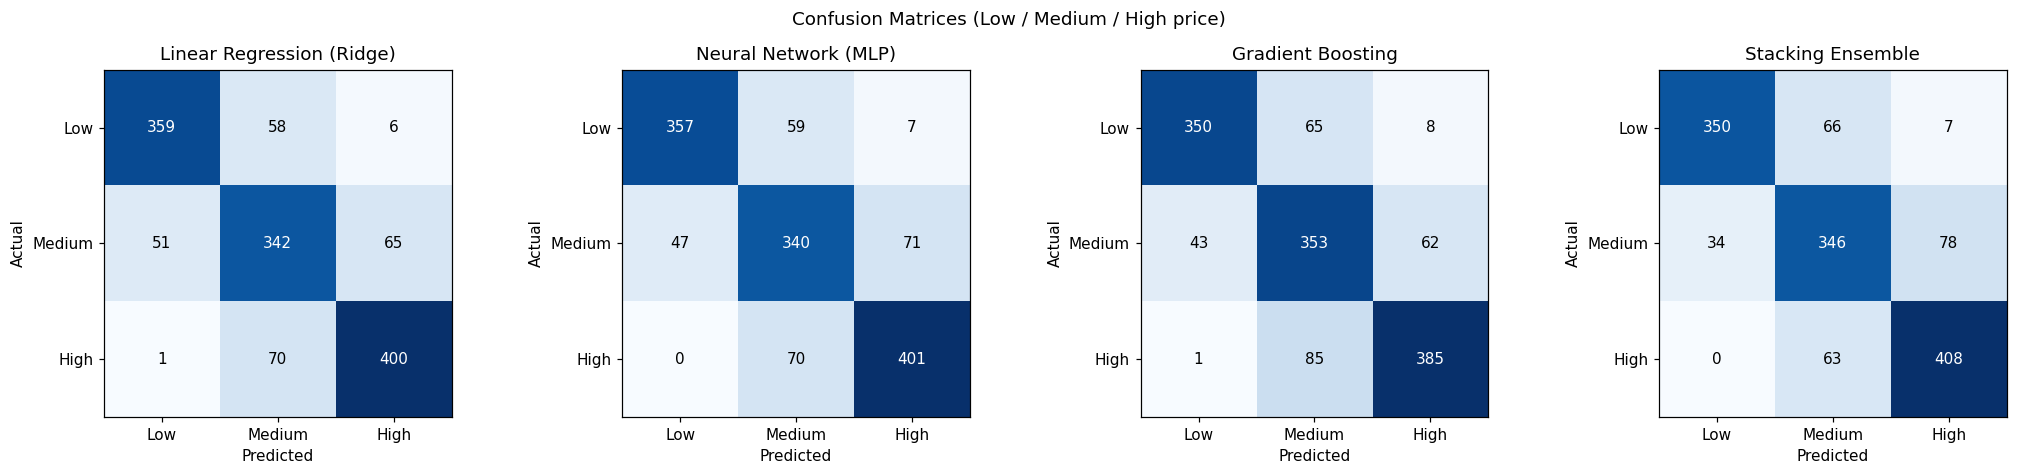

In [13]:
fig, axes = plt.subplots(1, 4, figsize=(19, 4.3))
for ax, (name, y_pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(to_band(y_test), to_band(y_pred), labels=labels)
    ax.imshow(cm, cmap="Blues")
    ax.set_xticks(range(3)); ax.set_xticklabels(labels)
    ax.set_yticks(range(3)); ax.set_yticklabels(labels)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, cm[i, j], ha="center", va="center",
                    color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual"); ax.set_title(name)
plt.suptitle("Confusion Matrices (Low / Medium / High price)")
plt.tight_layout(); plt.show()

### 7.3 Model comparison box plot — 10-fold cross-validated R² on the training set

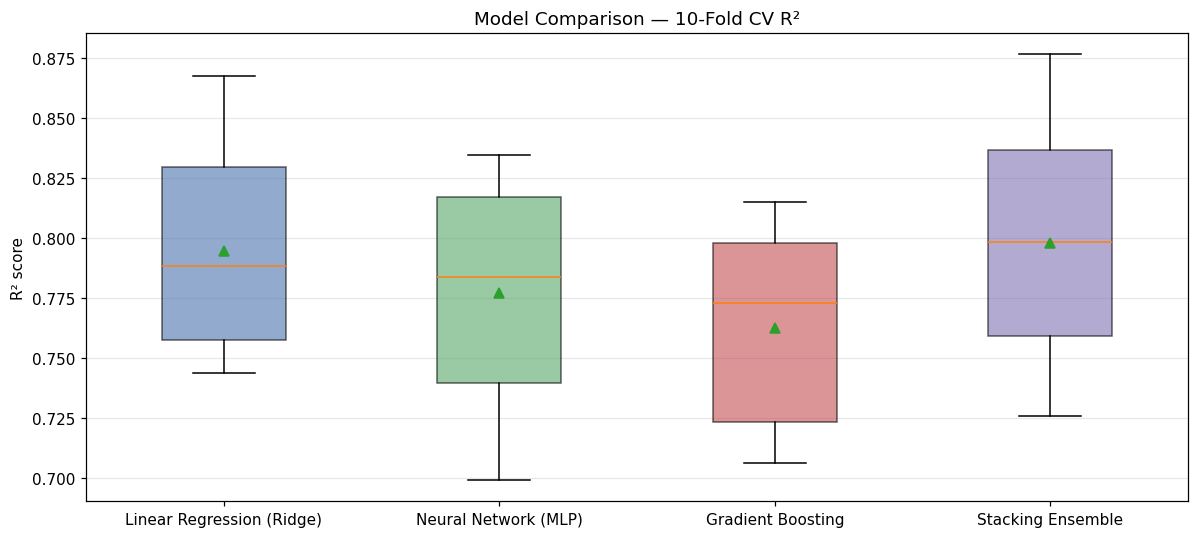

,mean,std
Linear Regression (Ridge),0.794390,0.044612
Neural Network (MLP),0.776845,0.048622
Gradient Boosting,0.762502,0.041046
Stacking Ensemble,0.797868,0.048149


In [14]:
kf = KFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)
cv_scores = {name: cross_val_score(model, X_train, y_train, cv=kf, scoring="r2", n_jobs=-1)
             for name, model in models.items()}

fig, ax = plt.subplots(figsize=(11, 5))
bp = ax.boxplot(cv_scores.values(), labels=cv_scores.keys(), patch_artist=True, showmeans=True)
for patch, color in zip(bp["boxes"], COLORS):
    patch.set_facecolor(color); patch.set_alpha(0.6)
ax.set_ylabel("R² score"); ax.set_title("Model Comparison — 10-Fold CV R²")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.show()

pd.DataFrame(cv_scores).agg(["mean", "std"]).T

### 7.4 Box plot of absolute prediction errors on the test set

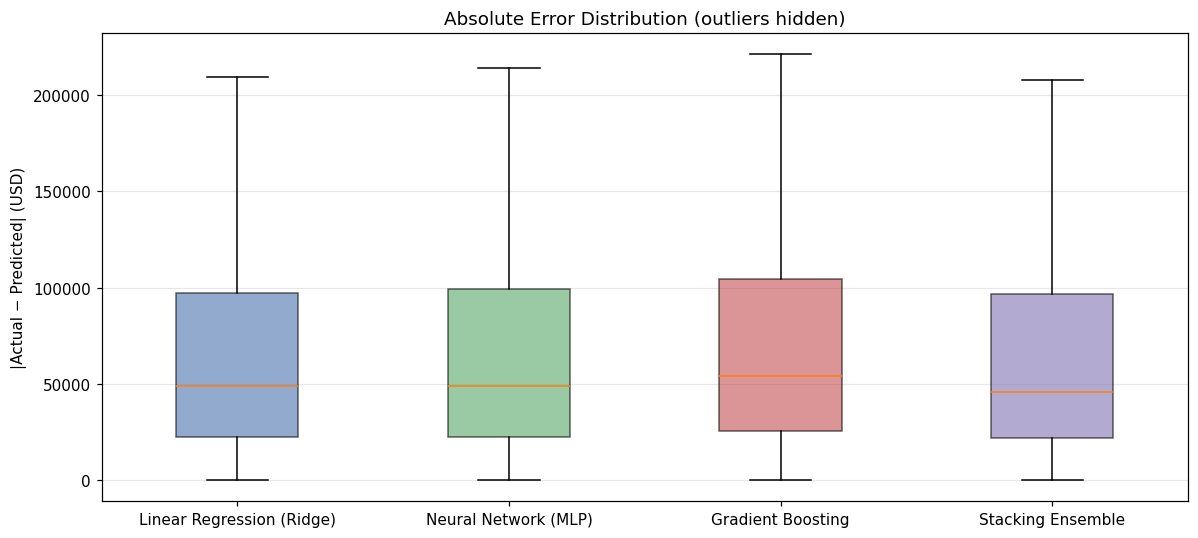

In [15]:
errors = {name: np.abs(y_test.values - p) for name, p in predictions.items()}
fig, ax = plt.subplots(figsize=(11, 5))
bp = ax.boxplot(errors.values(), labels=errors.keys(), patch_artist=True, showfliers=False)
for patch, color in zip(bp["boxes"], COLORS):
    patch.set_facecolor(color); patch.set_alpha(0.6)
ax.set_ylabel("|Actual − Predicted| (USD)"); ax.set_title("Absolute Error Distribution (outliers hidden)")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.show()

### 7.5 Metric and training-time bar charts

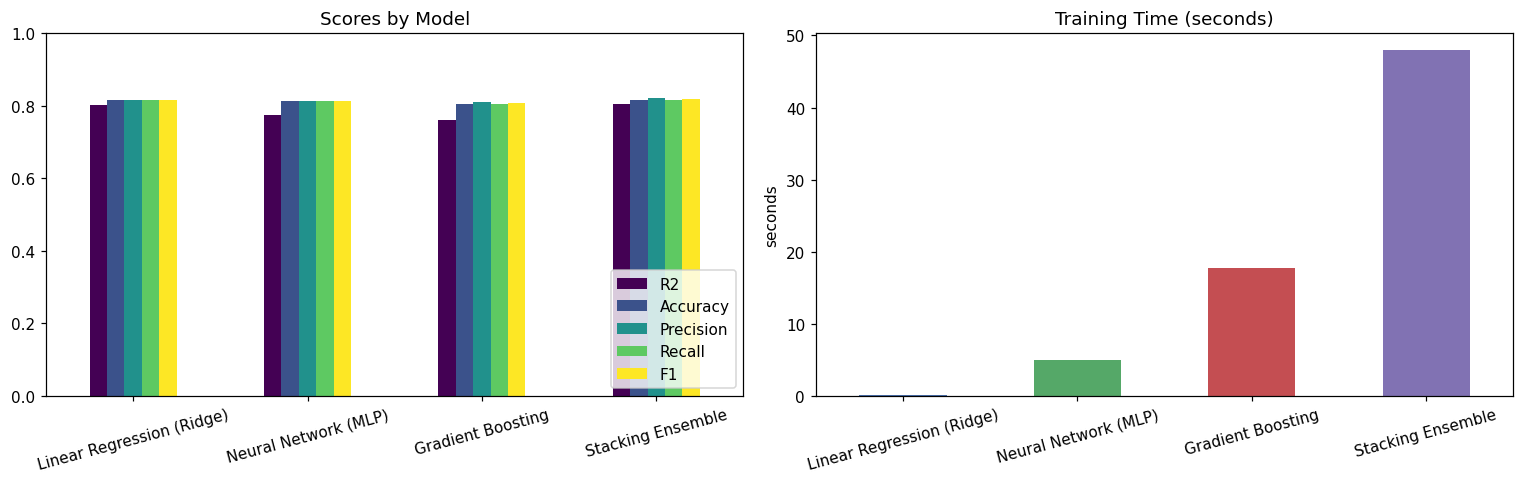

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
results_df[score_cols].plot(kind="bar", ax=axes[0], rot=15, colormap="viridis")
axes[0].set_ylim(0, 1); axes[0].set_title("Scores by Model"); axes[0].legend(loc="lower right")
results_df["Train Time (s)"].plot(kind="bar", ax=axes[1], rot=15, color=COLORS)
axes[1].set_title("Training Time (seconds)"); axes[1].set_ylabel("seconds")
for ax in axes: ax.set_xlabel("")
plt.tight_layout(); plt.show()

### 7.6 Actual vs. predicted prices

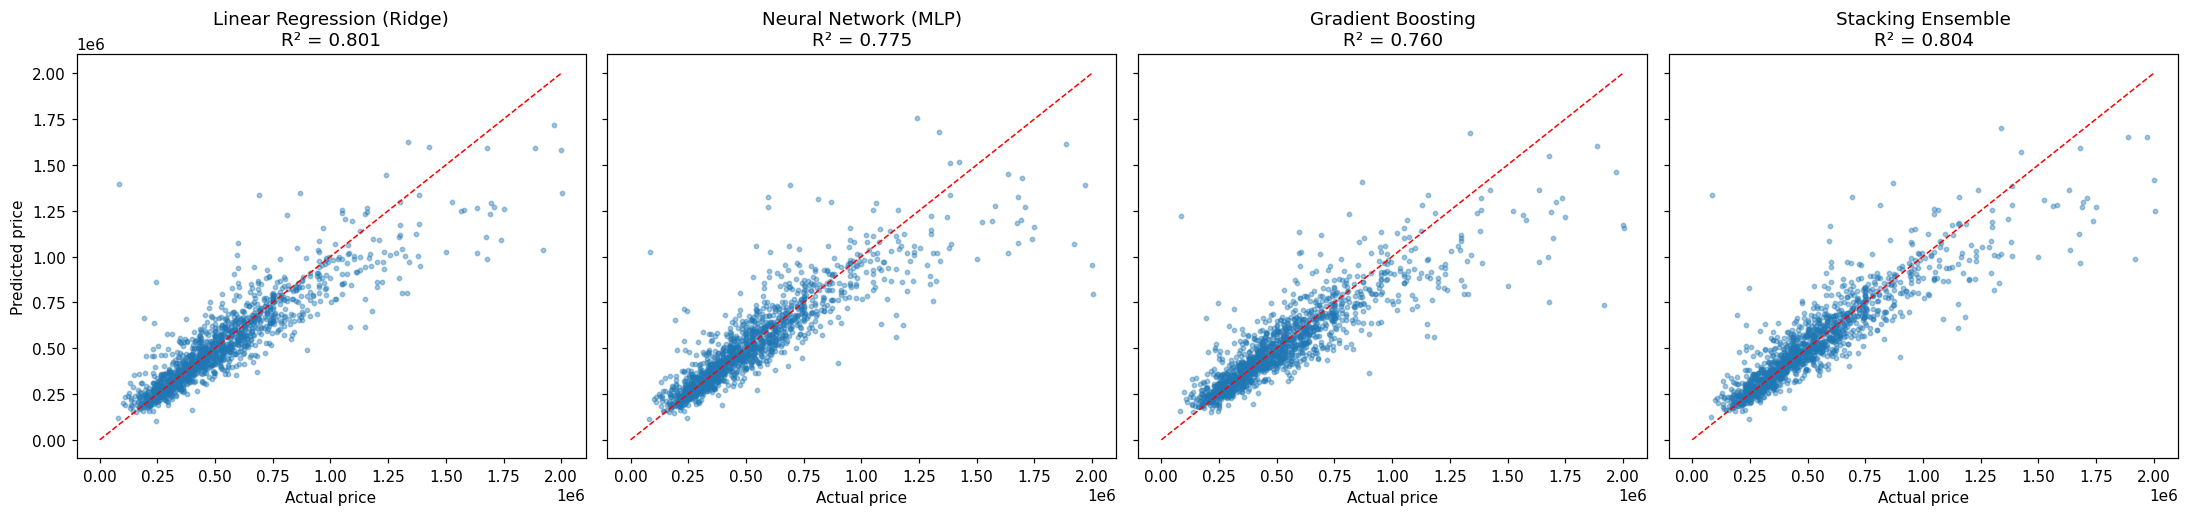

In [17]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4.8), sharey=True)
lim = [0, y_test.max()]
for ax, (name, y_pred) in zip(axes, predictions.items()):
    ax.scatter(y_test, y_pred, s=8, alpha=0.4)
    ax.plot(lim, lim, "r--", lw=1)
    ax.set_title(f"{name}\nR² = {r2_score(y_test, y_pred):.3f}")
    ax.set_xlabel("Actual price")
axes[0].set_ylabel("Predicted price")
plt.tight_layout(); plt.show()

## 8. Summary

In [18]:
best = results_df["R2"].idxmax()
print(f"Best model by R²: {best}")
print(results_df.loc[best].to_string())

Best model by R²: Stacking Ensemble
R2                     0.803969
MAE                77855.183488
RMSE              126148.387568
Accuracy               0.816568
Precision              0.820234
Recall                 0.816568
F1                     0.817529
Train Time (s)        47.920943
